# Scoring at the K threshold

> Score the Kex models as remediation uses them: which samples fall below the exchangeable K2O level that limits Cs-137 uptake by rice

In [ ]:
#| default_exp threshold

In [ ]:
#| export
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
from ossl_fuku_transfer.grouped import field_boots

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from fastcore.test import *
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import preprocessings, load_pretrained
from ossl_fuku_transfer.inside import layer_features
from ossl_fuku_transfer.grouped import group_folds, oof_preds

/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


After the accident, the main measure against Cs-137 uptake by rice was to keep exchangeable K high in paddy fields with extra K fertiliser. The decision for a field is therefore a threshold: is its exchangeable K2O below the target level? R² does not measure this. This notebook scores the Kex models of `20_grouped_cv` on the threshold instead.

A sample is *below* when its measured Kex is under the threshold. A model *flags* a sample when its prediction is at or below a cut-off. Flagged samples would go to the lab, or straight to K fertiliser. Missing a sample that is below can let rice exceed the food limit, so sensitivity, the share of samples below that are flagged, matters most. The cost of high sensitivity is the share of samples flagged, which is the lab workload.

The module part uses synthetic data, so it runs without the Fukushima data. The sections from *Data* onwards read the Fukushima data, and are marked `#| fukudata`.

## Flagging samples below the threshold

`flag_scores` scores one cut-off. By default the cut-off is the threshold itself, so a sample is flagged when its prediction is below the target level:

In [ ]:
#| export
def flag_scores(
    y, # Observed targets
    pred, # Predictions
    thr, # Threshold on the target scale; a sample under it is below
    cut=None, # Samples predicted at or below `cut` are flagged; `thr` if None
)->dict: # Sensitivity, specificity and share of samples flagged
    "Share of samples below `thr` that are flagged, share of the others that are not, and share flagged"
    y, pred = np.asarray(y), np.asarray(pred)
    below, flag = y < thr, pred <= (thr if cut is None else cut)
    return {'sensitivity': flag[below].mean(), 'specificity': (~flag[~below]).mean(), 'flagged': flag.mean()}

In [ ]:
rng = np.random.default_rng(0)
ys = rng.normal(size=200)
test_eq(flag_scores(ys, ys, 0), {'sensitivity': 1, 'specificity': 1, 'flagged': (ys <= 0).mean()})
test_eq(flag_scores(ys, ys + 10, 0)['flagged'], 0)
test_eq(flag_scores(ys, ys, 0, cut=10)['sensitivity'], 1)

`cut_at_sens` gives the cut-off that catches a set share of the samples below the threshold. The share of samples flagged at that cut-off is the lab workload needed to reach that sensitivity:

In [ ]:
#| export
def cut_at_sens(
    y, # Observed targets
    pred, # Predictions
    thr, # Threshold on the target scale
    sens=0.9, # Share of the samples below `thr` to flag
)->float: # The lowest cut-off that flags at least `sens` of them
    "Lowest cut-off for `flag_scores` that flags at least `sens` of the samples below `thr`"
    p = np.sort(np.asarray(pred)[np.asarray(y) < thr])
    return p[int(np.ceil(sens * len(p))) - 1]

In [ ]:
pn = ys + rng.normal(size=200)
c = cut_at_sens(ys, pn, 0)
test_eq(flag_scores(ys, pn, 0, c)['sensitivity'] >= 0.9, True)
test_eq(flag_scores(ys, pn, 0, c - 1e-9)['sensitivity'] < 0.9, True)
test_eq(cut_at_sens(ys, np.zeros(200), 0), 0)

`thr_scores` gives, for each model, the area under the ROC curve (AUC) for telling samples below the threshold from the others, the scores of `flag_scores` at the threshold, and the share flagged to reach `sens`. An AUC of 0.5 is chance and 1 is a perfect ranking. The intervals resample whole fields, as in `20_grouped_cv`. Each resample chooses its own cut-off for `sens`, so the workload interval includes the uncertainty in the cut-off:

In [ ]:
#| export
def thr_scores(
    y, # Observed targets of all samples
    preds:dict, # Model name: predictions of all samples
    thr, # Threshold on the target scale
    fields, # Field of every sample
    idx=None, # Positions of the samples to score; all if None
    sens=0.9, # Sensitivity for the workload column
    n_boot=1000, # Number of bootstrap resamples
    seed=0, # Seed for the bootstrap
)->pd.DataFrame: # One row per model
    "AUC, `flag_scores` at `thr` and share flagged to reach `sens`, with 95% intervals from `field_boots`"
    y, fields = np.asarray(y), np.asarray(fields)
    idx = np.arange(len(y)) if idx is None else np.asarray(idx)
    boots = field_boots(idx, fields, n_boot, seed)
    wl = f'flagged for {sens:.0%}'
    def two(i, p): return roc_auc_score(y[i] < thr, -p[i]), flag_scores(y[i], p[i], thr, cut_at_sens(y[i], p[i], thr, sens))['flagged']
    def ci(a, name): return dict(zip([f'{name} low', f'{name} high'], np.percentile(a, [2.5, 97.5])))
    rows = {}
    for m, p in preds.items():
        p = np.asarray(p)
        auc, fl = two(idx, p)
        b = np.array([two(i, p) for i in boots])
        rows[m] = {'n': len(idx), 'below': int((y[idx] < thr).sum()), 'AUC': auc, **ci(b[:, 0], 'AUC'),
                   **flag_scores(y[idx], p[idx], thr), wl: fl, **ci(b[:, 1], wl)}
    return pd.DataFrame.from_dict(rows, orient='index')

In [ ]:
fs = np.repeat(np.arange(40), 5)
ts = thr_scores(ys, {'perfect': ys, 'noisy': pn}, 0, fs, n_boot=50)
test_eq(ts.loc['perfect', 'AUC'], 1)
test_close(ts.loc['perfect', 'flagged for 90%'], 0.9 * (ys < 0).mean(), eps=0.01)
test_eq(ts.loc['noisy', 'AUC'] < 1, True)
test_eq(thr_scores(ys, {'perfect': ys}, 0, fs, idx=np.arange(100), n_boot=10).loc['perfect', 'n'], 100)

## Data and features

Kex as `log1p` of cmolc/kg, as in `20_grouped_cv`. The threshold is 25 mg K2O per 100 g of soil, which is the target level for exchangeable K2O in paddy fields in the remediation guidance as we understand it. The Fukushima data team should confirm the level they use. The share of samples below it, overall and by field type:

In [ ]:
#| fukudata
fuku = load_fuku()
props = fuku.source.reindex(fuku.sample_ids)
k2o = props['soil_ex_K2O'].to_numpy()
ok = np.isfinite(k2o)
y = np.log1p(k2o[ok] / mg_k2o_per_cmolc)
thr = np.log1p(25 / mg_k2o_per_cmolc)
fields, fieldtype, year = props['field_no'].astype(str).to_numpy()[ok], props['fieldtype'].to_numpy()[ok], props['year'].to_numpy()[ok]
pd.Series(y < thr).groupby(fieldtype).agg(['size', 'sum', 'mean']).round(3)

,size,sum,mean
grassland,3,0,0.000
paddy_field,880,440,0.500
upland_field,505,79,0.156


The share of samples below the threshold by year and field type. If K fertiliser drives Kex in paddy fields, the share below should change over the years as extra K is reduced:

In [ ]:
#| fukudata
pd.crosstab(year, fieldtype, values=y < thr, aggfunc='mean', rownames=['year'], colnames=['field type']).round(3)

field type,grassland,paddy_field,upland_field
year,,,
2013.0,NaN,0.758,0.245
2014.0,0.0,0.469,0.133
2015.0,NaN,0.340,0.216
2016.0,NaN,0.419,0.130
2017.0,NaN,0.518,0.157
2018.0,0.0,0.576,0.104
2019.0,0.0,0.516,0.150
2020.0,NaN,0.571,0.176


For fields sampled at least twice, the share of the variance of Kex that lies within fields, between their sampling years. Soil minerals change little between years, so a spectral model is unlikely to predict this share:

In [ ]:
#| fukudata
d = pd.DataFrame({'y': y, 'field': fields, 'type': fieldtype})
d = d[d.groupby('field')['y'].transform('size') >= 2]
within = (d.y - d.groupby('field')['y'].transform('mean'))**2
total = (d.y - d.groupby('type')['y'].transform('mean'))**2
pd.DataFrame({'samples': d.groupby('type').size(), 'fields': d.groupby('type')['field'].nunique(), 'within-field share': within.groupby(d.type).sum() / total.groupby(d.type).sum()}).round(3)

,samples,fields,within-field share
type,,,
grassland,3,2,0.005
paddy_field,800,193,0.280
upland_field,463,120,0.219


Three feature sets, each fitted with ridge regression: the spectra after SNV and a Savitzky-Golay first derivative, block 4 of the OSSL Kex and CEC models, and field type alone, as a baseline. The baseline predicts the mean Kex of each field type in the training folds. It shows what the spectra add beyond knowing that a field is a paddy field:

In [ ]:
#| fukudata
X_d = preprocessings()['snv_d1'].fit_transform(fuku.spectra)[ok]
B4 = [layer_features(load_pretrained(m), X_d)['block 4'] for m in ('ossl_kex_snv_d1', 'ossl_cec_snv_d1')]
feats = {'spectra': X_d, 'block 4, OSSL Kex + CEC': np.hstack(B4), 'field type': pd.get_dummies(fieldtype).to_numpy(float)}
{k: v.shape for k, v in feats.items()}

{'spectra': (1388, 1675),
 'block 4, OSSL Kex + CEC': (1388, 5120),
 'field type': (1388, 3)}

## Out-of-fold predictions

Two schemes, for the two uses. *Grouped by field* holds out whole fields, as in `20_grouped_cv`, and matches screening fields that were never sampled. *Later years* trains on 2013 to 2018 and predicts 2019 and 2020, and matches monitoring fields over the years. Most fields sampled in 2019 and 2020 were also sampled earlier, so this scheme lets the model know the field. In both, the ridge penalty is chosen by inner folds grouped by field. The later-years scheme also predicts 2013 to 2018 from 2019 and 2020, and those predictions are not scored:

In [ ]:
#| fukudata
ridge = (make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha': np.logspace(-1, 6, 15)})
later = year >= 2019
schemes = {'grouped by field': group_folds(fields), 'later years': later.astype(int)}
oof = {(s, f): oof_preds(*ridge, X, y, folds, fields)[0] for s, folds in schemes.items() for f, X in feats.items()}
print('later-years test samples:', later.sum(), '; share from fields sampled before 2019:', np.isin(fields[later], fields[~later]).mean().round(3))

later-years test samples: 334 ; share from fields sampled before 2019: 0.913


/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. Thi

## Scores at the threshold

With folds grouped by field, over all samples and within each field type. Within a field type, the field-type baseline predicts one value for every sample, so it is scored only over all samples. The 3 grassland samples count only in `all`:

In [ ]:
#| fukudata
def scores(s, groups):
    preds = lambda g: {f: oof[s, f] for f in feats if g == 'all' or f != 'field type'}
    return pd.concat({g: thr_scores(y, preds(g), thr, fields, idx) for g, idx in groups.items()})
cols = ['n', 'below', 'AUC', 'AUC low', 'AUC high', 'sensitivity', 'specificity', 'flagged', 'flagged for 90%', 'flagged for 90% low', 'flagged for 90% high']
by_type = lambda m: {'all': np.flatnonzero(m), 'paddy fields': np.flatnonzero(m & (fieldtype == 'paddy_field')), 'upland fields': np.flatnonzero(m & (fieldtype == 'upland_field'))}
t_field = scores('grouped by field', by_type(np.ones(len(y), bool)))
t_field[cols].round(3)

n  ...  flagged for 90% high
all           spectra                  1388  ...                 0.809
              block 4, OSSL Kex + CEC  1388  ...                 0.808
              field type               1388  ...                 0.920
paddy fields  spectra                   880  ...                 0.892
              block 4, OSSL Kex + CEC   880  ...                 0.883
upland fields spectra                   505  ...                 0.814
              block 4, OSSL Kex + CEC   505  ...                 0.830

[7 rows x 11 columns]

The same for the later-years scheme, scored on 2019 and 2020:

In [ ]:
#| fukudata
t_year = scores('later years', by_type(later))
t_year[cols].round(3)

n  ...  flagged for 90% high
all           spectra                  334  ...                 0.952
              block 4, OSSL Kex + CEC  334  ...                 0.927
              field type               334  ...                 1.000
paddy fields  spectra                  222  ...                 0.951
              block 4, OSSL Kex + CEC  222  ...                 0.952
upland fields spectra                  111  ...                 1.000
              block 4, OSSL Kex + CEC  111  ...                 1.000

[7 rows x 11 columns]

In paddy fields, the share of samples flagged against the share of samples below the threshold that are caught, as the cut-off moves. A model that ranks no better than chance follows the diagonal. Flagging every sample is the top right corner:

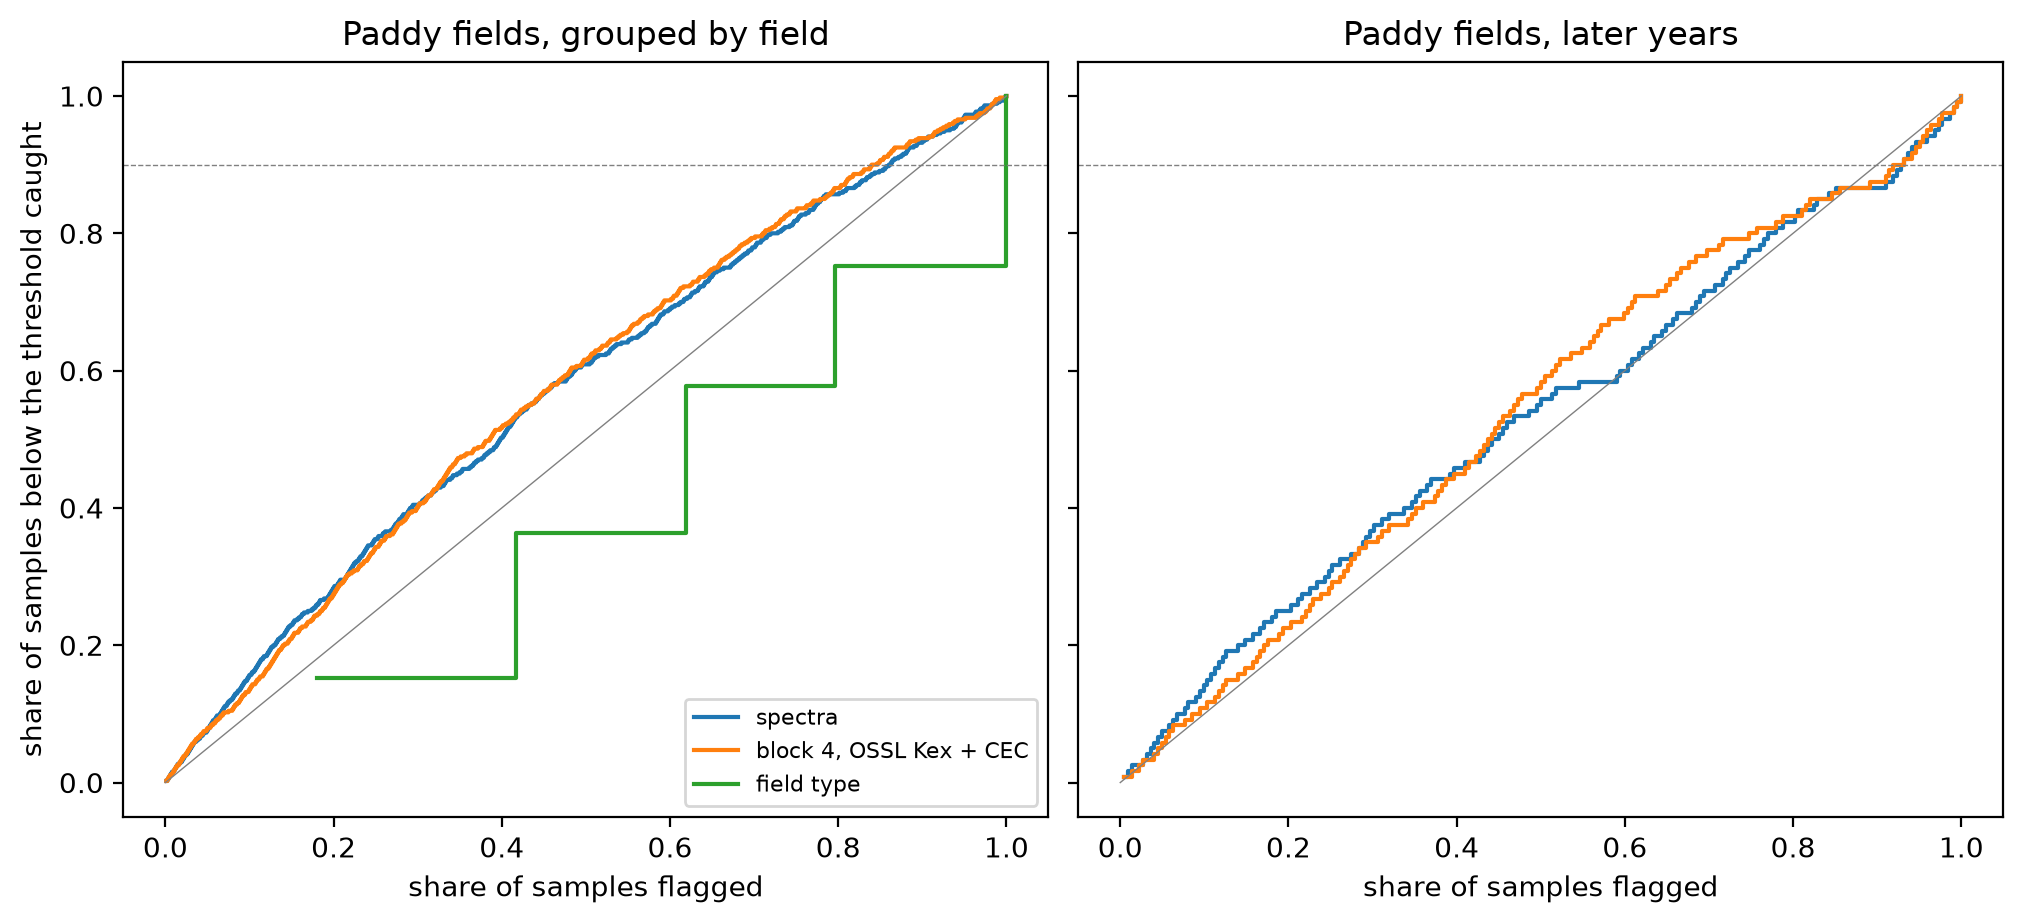

In [ ]:
#| fukudata
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), layout='constrained', sharey=True)
for ax, (s, m) in zip(axs, (('grouped by field', np.ones(len(y), bool)), ('later years', later))):
    i = np.flatnonzero(m & (fieldtype == 'paddy_field'))
    for f in feats:
        p = oof[s, f][i]
        cuts = np.unique(p)
        ax.step([flag_scores(y[i], p, thr, c)['flagged'] for c in cuts], [flag_scores(y[i], p, thr, c)['sensitivity'] for c in cuts], where='post', label=f)
    ax.plot([0, 1], [0, 1], c='grey', lw=0.5); ax.axhline(0.9, c='grey', lw=0.5, ls='--')
    ax.set(title=f'Paddy fields, {s}', xlabel='share of samples flagged')
axs[0].set_ylabel('share of samples below the threshold caught'); axs[0].legend(fontsize=8);

## Findings

Spectral models cannot yet replace lab tests for the K threshold in paddy fields. With folds grouped by field, ridge on the spectra ranks paddy samples below 25 mg K2O per 100 g with an AUC of 0.65 (95% interval 0.60 to 0.70). To catch 90% of the paddy samples below the threshold, it must flag 86% of all paddy samples (0.81 to 0.89). Compared with testing every paddy sample, that saves only 14% of the lab work. Block 4 of the OSSL Kex and CEC models does the same: AUC 0.65, with 84% flagged.

Taken at the threshold itself, the predictions miss most samples below it. Flagging the samples predicted below 25 mg catches 41% of the samples below it overall, and 44% in paddy fields. Ridge regression pulls predictions towards the mean Kex, which is 35 mg overall. A screen needs a cut-off above the threshold, chosen for the sensitivity required.

Across all samples, much of the ranking comes from field type. 50% of paddy samples are below the threshold, against 16% of upland samples. Field type alone gives an AUC of 0.64, against 0.72 for the spectra. Within upland fields the spectra rank better, at AUC 0.72 (0.64 to 0.80), but only 79 upland samples are below the threshold.

On later years, the models do worse, though 91% of the 2019 and 2020 samples come from fields sampled before. Trained on 2013 to 2018, ridge on the spectra gives an AUC of 0.64 (0.57 to 0.70) on 2019 and 2020, and field type alone gives 0.68 (0.62 to 0.73). In paddy fields the AUC is 0.57 (0.48 to 0.64), and catching 90% of the samples below the threshold means flagging 93% of them. For monitoring known fields, the spectra do no better than field type.

The pattern over the years fits K fertiliser. The share of paddy samples below the threshold fell from 76% in 2013 to 34% in 2015, then rose to 57% by 2020. In fields sampled at least twice, 28% of the variance of paddy Kex lies within fields, between sampling years. Soil minerals change little over a few years, so the spectra are unlikely to follow these changes. Whether the rise after 2015 matches less K fertiliser is a question for the Fukushima data team.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()